# Morphological Black Top-Hat for Crevasse Enhancement

## Objective
Explore morphological black top-hat as an image enhancement method
to make dark crevasse features more visible in NISAR satellite images.

## Method
Black top-hat highlights dark features that are smaller than a
specified structuring element.

We will:
1. Load a sample NISAR radar image.
2. Apply morphological black top-hat.
3. Compare different structuring element sizes.
4. Evaluate whether crevasses become easier to identify.

In [6]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Locate NISAR data in Box
data_dir = (
    Path.home()
    / "Library/CloudStorage/Box-Box/2026-glaciers/nisar_data/nisar_gcov_pig"
)

# Select the first HDF5 file
file_path = sorted(data_dir.glob("*.h5"))[0]

# Read a small sample from frequency B
with h5py.File(file_path, "r") as f:
    dataset = f["science/LSAR/GCOV/grids/frequencyB/HHHH"]
    image = dataset[2500:3500, 1500:2500]

print("Image shape:", image.shape)
print("Data type:", image.dtype)
print("Valid pixels:", np.isfinite(image).sum())

Image shape: (1000, 1000)
Data type: float32
Valid pixels: 1000000


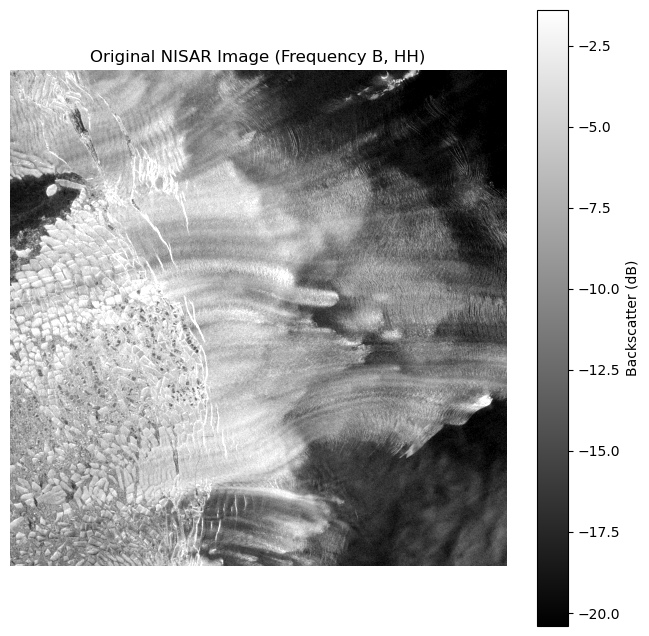

In [7]:
# Convert positive backscatter values to decibels
image_db = np.full(image.shape, np.nan, dtype=np.float32)

valid = np.isfinite(image) & (image > 0)
image_db[valid] = 10 * np.log10(image[valid])

# Display using percentile-based contrast
if np.any(valid):
    vmin, vmax = np.percentile(image_db[valid], [2, 98])

    plt.figure(figsize=(8, 8))
    plt.imshow(image_db, cmap="gray", vmin=vmin, vmax=vmax)
    plt.title("Original NISAR Image (Frequency B, HH)")
    plt.colorbar(label="Backscatter (dB)")
    plt.axis("off")
    plt.show()
else:
    print("No valid positive backscatter values in this sample.")

In [8]:
import sys
from pathlib import Path

# Add the project's src directory to Python's import path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

from utils.inference_strategies.black_tophat import apply_black_tophat

In [9]:
# Prepare image for morphological processing
valid = np.isfinite(image_db)

if not np.any(valid):
    raise ValueError("No valid image pixels found.")

# Replace NaN values with the median for this initial test
image_clean = np.where(
    valid,
    image_db,
    np.nanmedian(image_db)
)

# Test three structuring element sizes
radii = [3, 5, 10]

results = {
    radius: apply_black_tophat(image_clean, radius=radius)
    for radius in radii
}

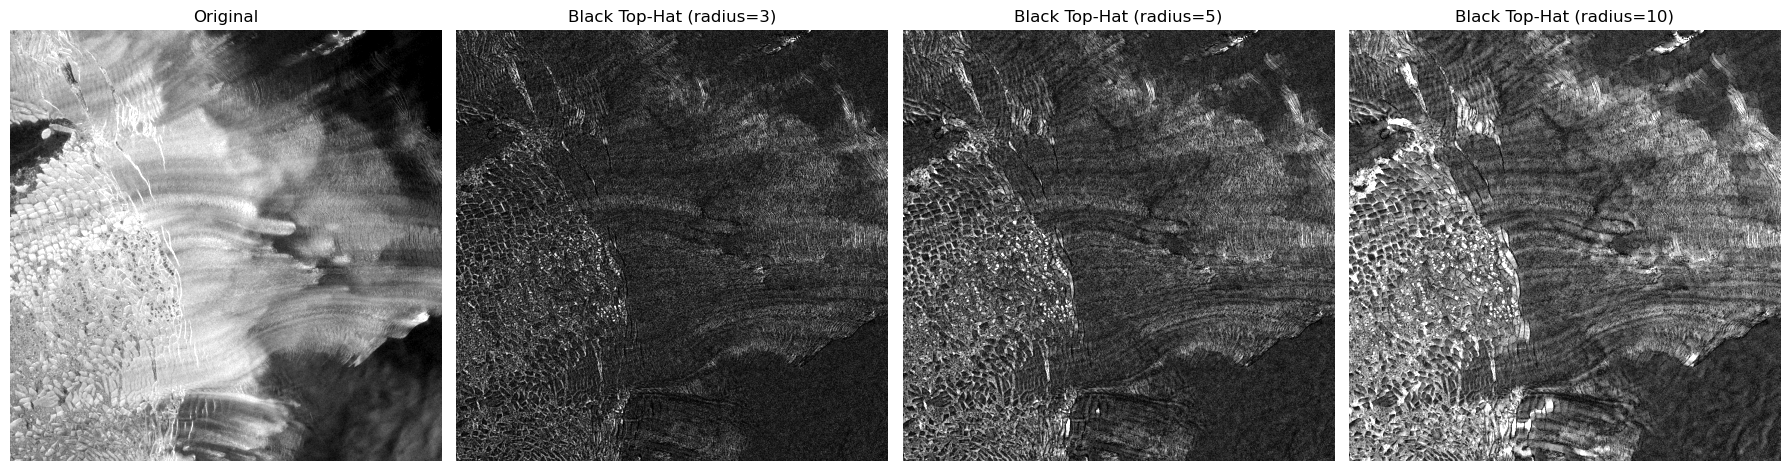

In [11]:
# Use a shared contrast scale for all black top-hat results
all_values = np.concatenate([
    results[r].ravel() for r in radii
])

response_max = np.percentile(all_values, 99)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original")

for ax, radius in zip(axes[1:], radii):
    ax.imshow(
        results[radius],
        cmap="gray",
        vmin=0,
        vmax=response_max
    )
    ax.set_title(f"Black Top-Hat (radius={radius})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

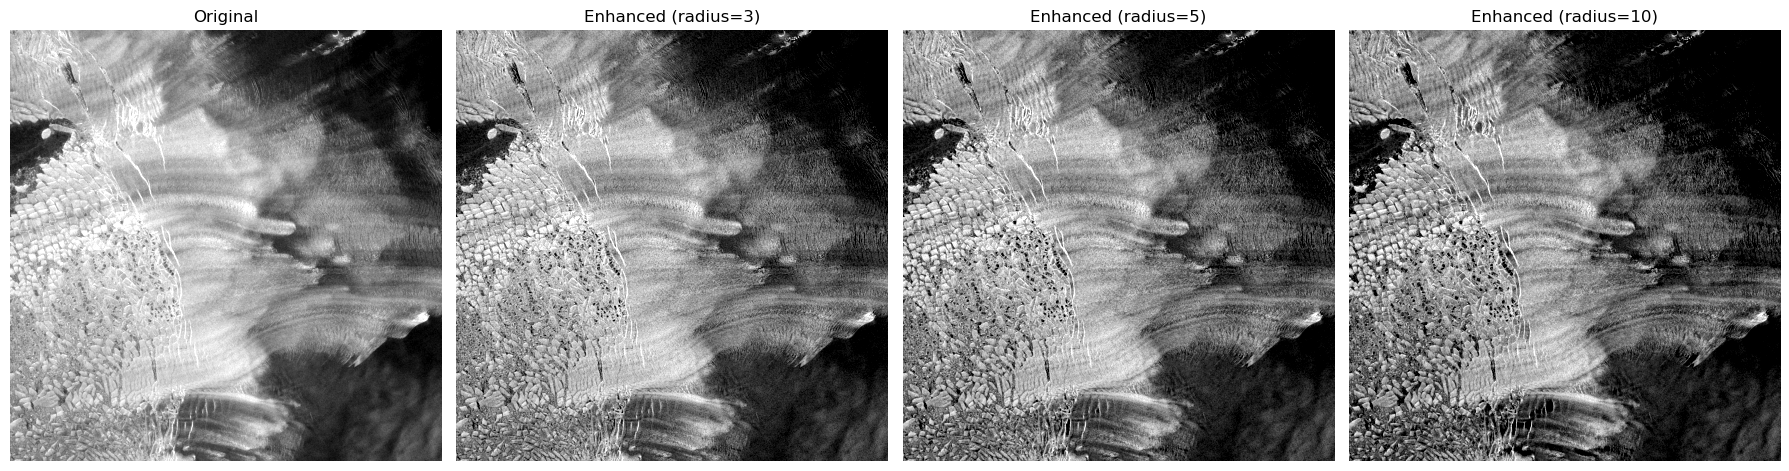

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_clean, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original")

for ax, radius in zip(axes[1:], radii):
    # Darken features identified by black top-hat
    enhanced = image_clean - results[radius]

    ax.imshow(enhanced, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(f"Enhanced (radius={radius})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()